In [ ]:

from google.colab import files

uploaded = files.upload()


Saving sms+spam+collection.zip to sms+spam+collection.zip


In [ ]:
import zipfile
import io
import pandas as pd

# Get the uploaded ZIP file
file_name = list(uploaded.keys())[0]

# Extract and read the SMS dataset
with zipfile.ZipFile(io.BytesIO(uploaded[file_name])) as zip_file:

    print("Files inside ZIP:", zip_file.namelist())

    with zip_file.open("SMSSpamCollection") as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Files inside ZIP: ['SMSSpamCollection', 'readme']
Dataset loaded successfully!
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing Values:
label      0
message    0
dtype: int64

First 5 Rows:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSpam and Ham Message Count:")
print(df['label'].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing Values:
label      0
message    0
dtype: int64

Spam and Ham Message Count:
label
ham     4825
spam     747
Name: count, dtype: int64


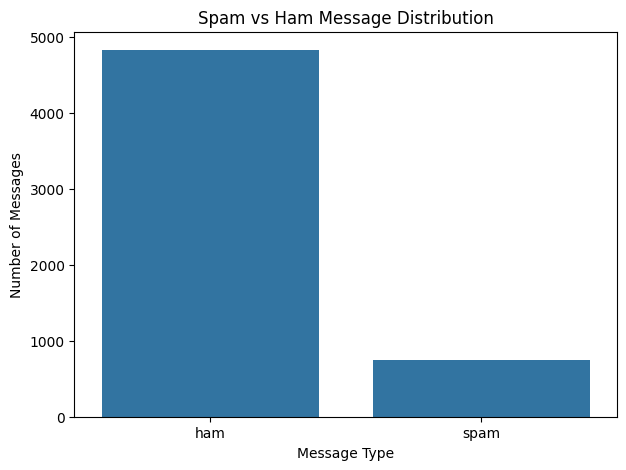

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='label')

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")

plt.show()

In [ ]:
label_counts = df['label'].value_counts()

percentage = df['label'].value_counts(normalize=True) * 100

print("Message Count:")
print(label_counts)

print("\nMessage Percentage:")
print(percentage.round(2))

Message Count:
label
ham     4825
spam     747
Name: count, dtype: int64

Message Percentage:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


In [ ]:
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

print("Label Encoding Completed!")
display(df.head())

Label Encoding Completed!


,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
print("Dataset Shape:", df.shape)

print("\nUpdated Label Values:")
print(df['label'].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (5572, 2)

Updated Label Values:
label
0    4825
1     747
Name: count, dtype: int64

Missing Values:
label      0
message    0
dtype: int64


In [ ]:
import re
import string

# Function to clean text messages
def clean_text(text):

    # Convert text into lowercase
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r'[^\w\s]', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Apply text cleaning
df['clean_message'] = df['message'].apply(clean_text)

print("Text Cleaning Completed Successfully!")

display(df[['message', 'clean_message']].head(10))

Text Cleaning Completed Successfully!


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling its been 3 weeks now...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,Had your mobile 11 months or more? U R entitle...,had your mobile 11 months or more u r entitled...


In [ ]:
X = df['clean_message']
y = df['label']

print("Input Data Shape:", X.shape)
print("Output Data Shape:", y.shape)

print("\nSample Input Messages:")
display(X.head())

print("\nSample Output Labels:")
print(y.head())

Input Data Shape: (5572,)
Output Data Shape: (5572,)

Sample Input Messages:


,clean_message
0,go until jurong point crazy available only in ...
1,ok lar joking wif u oni
2,free entry in 2 a wkly comp to win fa cup fina...
3,u dun say so early hor u c already then say
4,nah i dont think he goes to usf he lives aroun...



Sample Output Labels:
0    0
1    0
2    1
3    0
4    0
Name: label, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset Splitting Completed!")
print("--------------------------------")
print("Training Messages:", len(X_train))
print("Testing Messages:", len(X_test))
print("Training Labels:", len(y_train))
print("Testing Labels:", len(y_test))

Dataset Splitting Completed!
--------------------------------
Training Messages: 4457
Testing Messages: 1115
Training Labels: 4457
Testing Labels: 1115


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    min_df=1,
    stop_words='english'
)

# Convert text into numerical features
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Feature Extraction Completed!")
print("--------------------------------------")
print("Training Matrix Shape:", X_train_tfidf.shape)
print("Testing Matrix Shape:", X_test_tfidf.shape)

TF-IDF Feature Extraction Completed!
--------------------------------------
Training Matrix Shape: (4457, 8099)
Testing Matrix Shape: (1115, 8099)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_tfidf, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [ ]:
# Predict test messages
y_pred = model.predict(X_test_tfidf)

print("Predictions Completed Successfully!")

print("\nFirst 10 Actual Labels:")
print(y_test.values[:10])

print("\nFirst 10 Predicted Labels:")
print(y_pred[:10])

Predictions Completed Successfully!

First 10 Actual Labels:
[0 0 0 1 0 0 0 0 0 0]

First 10 Predicted Labels:
[0 0 0 1 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("MODEL PERFORMANCE")
print("--------------------------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

MODEL PERFORMANCE
--------------------------------
Accuracy : 96.5 %
Precision: 100.0 %
Recall   : 73.83 %
F1 Score : 84.94 %


In [ ]:
from sklearn.metrics import classification_report

print("CLASSIFICATION REPORT")
print("--------------------------------")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Ham', 'Spam'],
    zero_division=0
))

CLASSIFICATION REPORT
--------------------------------
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       1.00      0.74      0.85       149

    accuracy                           0.97      1115
   macro avg       0.98      0.87      0.91      1115
weighted avg       0.97      0.97      0.96      1115



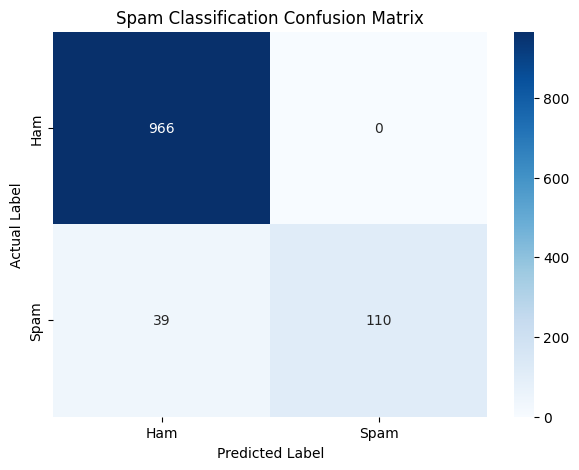

Confusion Matrix:
[[966   0]
 [ 39 110]]


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title("Spam Classification Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

print("Confusion Matrix:")
print(cm)


In [ ]:
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

results['Actual'] = results['Actual'].map({
    0: 'Ham',
    1: 'Spam'
})

results['Predicted'] = results['Predicted'].map({
    0: 'Ham',
    1: 'Spam'
})

display(results.head(15))

,Actual,Predicted
0,Ham,Ham
1,Ham,Ham
2,Ham,Ham
3,Spam,Spam
4,Ham,Ham
5,Ham,Ham
6,Ham,Ham
7,Ham,Ham
8,Ham,Ham
9,Ham,Ham


In [ ]:
def predict_message(message):

    # Clean the input message
    cleaned_message = clean_text(message)

    # Convert message into TF-IDF features
    message_vector = tfidf.transform([cleaned_message])

    # Predict message category
    prediction = model.predict(message_vector)[0]

    # Calculate prediction probabilities
    probability = model.predict_proba(message_vector)[0]

    print("------------------------------------")
    print("       SPAM MESSAGE CLASSIFIER")
    print("------------------------------------")

    print("\nEntered Message:")
    print(message)

    if prediction == 1:
        print("\nRESULT: SPAM MESSAGE")
        print("Warning: This message may be unwanted or fraudulent.")

    else:
        print("\nRESULT: HAM MESSAGE")
        print("This message is classified as legitimate.")

    print("\nSpam Probability:",
          round(probability[1] * 100, 2), "%")

    print("Ham Probability:",
          round(probability[0] * 100, 2), "%")

    print("------------------------------------")

    return prediction

In [ ]:
predict_message(
    "Congratulations! You won a free prize. Click here to claim now!"
)

------------------------------------
       SPAM MESSAGE CLASSIFIER
------------------------------------

Entered Message:
Congratulations! You won a free prize. Click here to claim now!

RESULT: SPAM MESSAGE

Spam Probability: 93.12 %
Ham Probability: 6.88 %
------------------------------------


np.int64(1)

In [ ]:
predict_message(
    "Hello, how are you? Are you coming to college tomorrow?"
)

------------------------------------
       SPAM MESSAGE CLASSIFIER
------------------------------------

Entered Message:
Hello, how are you? Are you coming to college tomorrow?

RESULT: HAM MESSAGE
This message is classified as legitimate.

Spam Probability: 4.66 %
Ham Probability: 95.34 %
------------------------------------


np.int64(0)

In [ ]:
import joblib

# Save trained Logistic Regression model
joblib.dump(model, 'spam_classifier_model.pkl')

# Save TF-IDF vectorizer
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("Model and TF-IDF Vectorizer Saved Successfully!")

Model and TF-IDF Vectorizer Saved Successfully!


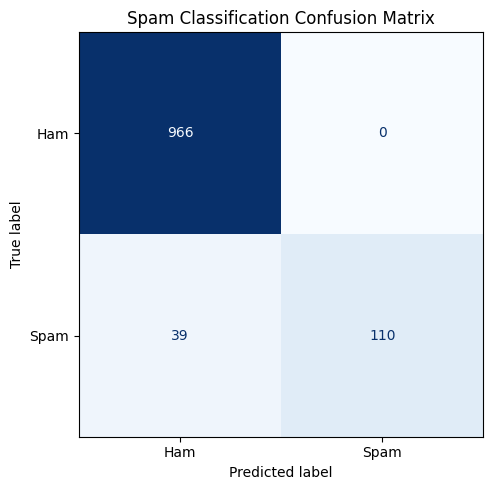

Confusion Matrix Saved Successfully!


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Ham', 'Spam']
).plot(
    ax=ax,
    cmap='Blues',
    colorbar=False
)

plt.title("Spam Classification Confusion Matrix")
plt.tight_layout()

plt.savefig('confusion_matrix.png', dpi=300)

plt.show()

print("Confusion Matrix Saved Successfully!")

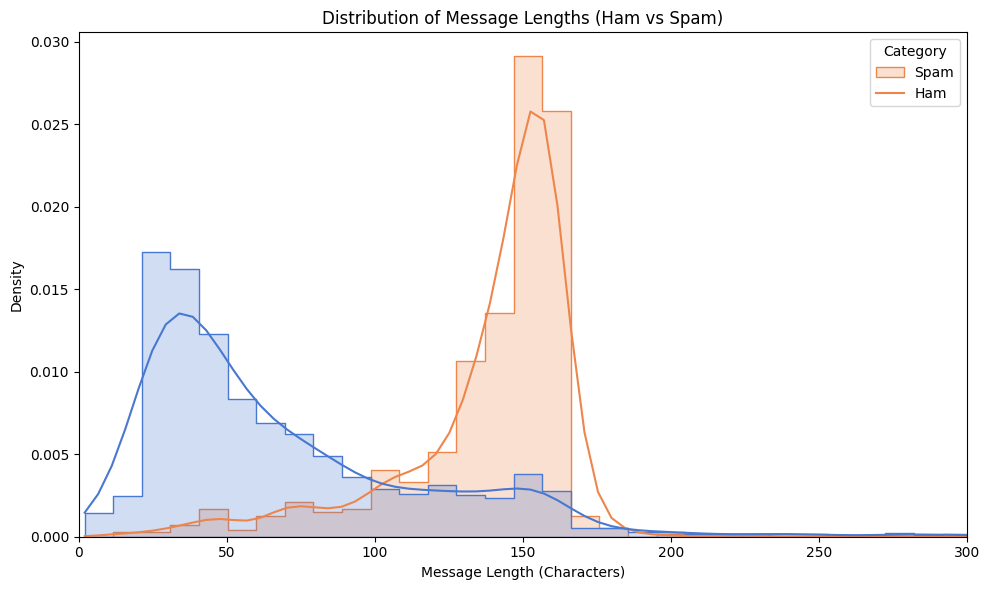

Average length of Ham messages: 71.48 characters
Average length of Spam messages: 138.67 characters


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate message lengths (number of characters)
df['message_len'] = df['message'].apply(len)

# Plot distribution of message lengths for Ham vs Spam
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='message_len',
    hue='label',
    kde=True,
    element='step',
    stat='density',
    common_norm=False,
    palette='muted'
)

plt.title("Distribution of Message Lengths (Ham vs Spam)")
plt.xlabel("Message Length (Characters)")
plt.ylabel("Density")
plt.legend(title="Category", labels=["Spam", "Ham"])
plt.xlim(0, 300)  # Limit x-axis to focus on the main bulk of messages

plt.tight_layout()
plt.show()

# Show descriptive statistics for message lengths
print("Average length of Ham messages:", round(df[df['label'] == 0]['message_len'].mean(), 2), "characters")
print("Average length of Spam messages:", round(df[df['label'] == 1]['message_len'].mean(), 2), "characters")

In [ ]:
df[['label', 'message']].to_csv(
    'spam_dataset.csv',
    index=False
)

print("Dataset Saved Successfully!")

Dataset Saved Successfully!


In [ ]:
requirements = """
numpy
pandas
matplotlib
seaborn
scikit-learn
joblib
"""

with open('requirements.txt', 'w') as file:
    file.write(requirements.strip())

print("requirements.txt Created Successfully!")

requirements.txt Created Successfully!


In [ ]:
from google.colab import files

files.download('spam_classifier_model.pkl')
files.download('tfidf_vectorizer.pkl')
files.download('confusion_matrix.png')
files.download('spam_dataset.csv')
files.download('requirements.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>